# Hipótesis: agua, área urbana y aeropuerto/ASOS vs. error de pronóstico

**Hipótesis**: *la distancia a un cuerpo de agua, a un área urbana o al aeropuerto
más cercano se asocia al error de pronóstico.*

- H0: la distancia (o la pertenencia al grupo "sobre agua" / "área urbana") no se asocia ni al error absoluto (MAE)
  ni al sesgo con signo.
- H1: sí se asocia, en magnitud y/o en dirección.

## Disponibilidad de datos
Se tienen en cuenta los siguientes conjuntos de datos para testear la hipótesis:
- Natural Earth 10m (coastline + lakes)
- Census Gazeteer - Places 2020
- EPA Ecoregions Level III (CONUS)
- OurAirports (airports.csv)

Estas fuentes se cruzaron con las estaciones en `ETL/atributos_geograficos.py` → `data/processed/estaciones_atributos.csv`. Con dos aproximaciones, declaradas como limitación:

- **Aeropuerto/ASOS**: no hay una lista separada de estaciones ASOS (la red que calibra el modelo del NWS). Se usa
  la distancia al aeropuerto `medium`/`large` más cercano (OurAirports) como proxy, porque los ASOS suelen estar
  en aeropuertos de ese tamaño.
- **Área urbana**: el Gazetteer de ciudades del Census no trae población. Se usa en cambio la categoría propia del
  Census (`UATYP20`): *Urbanized Area* (≥ 50.000 hab.) vs *Urban Cluster* (2.500–49.999 hab.).

**Convención de signo**: igual que en `patrones-temporales.ipynb`, error = **pronosticado − observado** (positivo =
sobreestima). 
**Unidad de análisis**: una fila por estación (sesgo y MAE agregados), no por hora, para no inflar el
n con observaciones autocorrelacionadas.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
from matplotlib.colors import LogNorm
from scipy import stats
from statsmodels.stats.multitest import multipletests
from utils import AZUL, NARANJA, GRIS_TEXTO, SECUENCIAL, aplicar_estilo, cargar_mediciones_limpias

In [2]:
OUT = '../data/processed/hipotesis/'
PROCESSED = '../data/processed/'

aplicar_estilo()
figuras = {}  # se exportan todas al final

## 1. Carga y preparación de los datos (una fila por estación)

In [3]:
MIN_OBS = 30  # mínimo de pares estación-hora para entrar (mismo criterio que atributos_geograficos.py)

VARIABLES = {
    'temp_c': 'Temperatura (°C)',
    'rh_pct': 'Humedad relativa (pp)',
    'dewpoint_c': 'Punto de rocío (°C)',
    'windspeed_kmh': 'Viento (km/h)',
}
columnas_error = [f'{pref}_{v}' for v in VARIABLES for pref in ('error', 'abs_error')]

mp = cargar_mediciones_limpias()
atributos = pd.read_csv('../data/processed/estaciones_atributos.csv')

agrupado = mp.groupby('station_id')
por_estacion = agrupado[columnas_error].mean()
por_estacion['n_obs'] = agrupado.size()
por_estacion['red'] = agrupado['red'].first()  # para controlar por red en la sección 4

pocas_obs = por_estacion['n_obs'] < MIN_OBS
coords = mp.groupby('station_id')[['latitud', 'longitud']].first()
datos = (por_estacion[~pocas_obs]
         .join(atributos.set_index('station_id'), how='inner')
         .join(coords))

# dist_ciudad_50k_km coincide con dist_area_urbana_km en estas 500 estaciones (el área urbana más
# cercana siempre resultó ser una Urbanized Area >= 50.000 hab.): se usa solo dist_area_urbana_km
# para no repetir el mismo test dos veces.
assert (datos['dist_area_urbana_km'] == datos['dist_ciudad_50k_km']).all()

print(f'{len(datos)} estaciones con >= {MIN_OBS} pares y atributos geográficos '
      f'({pocas_obs.sum()} excluidas por pocas observaciones, '
      f'{len(atributos) - len(por_estacion)} sin ninguna medición limpia)')
print(f"  sobre el agua: {datos['sobre_agua'].sum()}   en área urbana: {datos['en_area_urbana'].sum()}")
datos[['dist_agua_km', 'dist_aeropuerto_km', 'dist_area_urbana_km']].describe().round(1)

344 estaciones con >= 30 pares y atributos geográficos (1 excluidas por pocas observaciones, 155 sin ninguna medición limpia)
  sobre el agua: 7   en área urbana: 166


,dist_agua_km,dist_aeropuerto_km,dist_area_urbana_km
count,344.0,344.0,344.0
mean,186.5,29.6,5.8
std,233.0,22.5,10.7
min,0.0,0.8,0.0
25%,16.6,12.4,0.0
50%,76.8,22.3,0.0
75%,292.0,42.8,8.1
max,1094.7,117.2,87.2


## 2. Análisis exploratorio breve

Dónde están las estaciones y qué tan cerca están del agua, de un área urbana y de un aeropuerto, y después el MAE
por estación contra esas tres distancias (escala log) y el sesgo con signo según pertenezca o no a cada grupo
binario (sobre el agua / en área urbana).

### Mapas de cercanía

In [4]:
CRS_METRICO = 'EPSG:5070'  # Albers equivalente para EE.UU. contiguo (igual que atributos_geograficos.py)
estados_mapa = gpd.read_file(PROCESSED + 'estados_central.geojson').to_crs(CRS_METRICO)
houston = gpd.GeoSeries(gpd.points_from_xy([-96.25, -94.65], [29.3, 30.55]), crs='EPSG:4326').to_crs(CRS_METRICO)

gdf = gpd.GeoDataFrame(datos, geometry=gpd.points_from_xy(datos['longitud'], datos['latitud']),
                       crs='EPSG:4326').to_crs(CRS_METRICO)


def mapa_cercania(ax, columna, etiqueta, titulo):
    """Mapa de estaciones coloreadas por distancia (escala log, más oscuro = más lejos = menos cercanía)."""
    valor = gdf[columna].clip(lower=0.1)  # la escala log no admite 0 (estaciones adentro del área/agua)
    orden = valor.sort_values(ascending=False).index  # las más cercanas (claras) quedan encima
    norma = LogNorm(vmin=valor.min(), vmax=valor.max())

    def dibujar(eje, tam):
        estados_mapa.plot(ax=eje, color='#ebeae6', edgecolor='white', linewidth=1.2)
        return eje.scatter(gdf.geometry.x[orden], gdf.geometry.y[orden], c=valor[orden], cmap=SECUENCIAL,
                           norm=norma, s=tam, edgecolor='white', linewidth=0.4, zorder=3)

    puntos = dibujar(ax, 24)
    for _, fila in estados_mapa.iterrows():
        p = fila.geometry.representative_point()
        ax.annotate(fila['estado'], (p.x, p.y), ha='center', va='center', fontsize=7, color=GRIS_TEXTO,
                   fontweight='bold', alpha=0.6, zorder=2)

    axins = ax.inset_axes([0.73, 0.29, 0.27, 0.22])  # hueco al este de Arkansas, como en distribucion-errores.ipynb
    dibujar(axins, 28)
    axins.set_xlim(houston.x.min(), houston.x.max())
    axins.set_ylim(houston.y.min(), houston.y.max())
    axins.set_xticks([]), axins.set_yticks([])
    axins.set_xlabel(''), axins.set_ylabel('')
    axins.grid(False)
    for borde in axins.spines.values():
        borde.set_visible(True), borde.set_edgecolor(GRIS_TEXTO), borde.set_linewidth(0.8)
    axins.set_title('Houston', fontsize=8, fontweight='normal', color=GRIS_TEXTO)
    ax.indicate_inset_zoom(axins, edgecolor=GRIS_TEXTO, alpha=0.8)

    ax.figure.colorbar(puntos, ax=ax, shrink=0.5, pad=0.01, label=etiqueta)
    ax.set_title(titulo, fontsize=11)
    ax.set_axis_off()

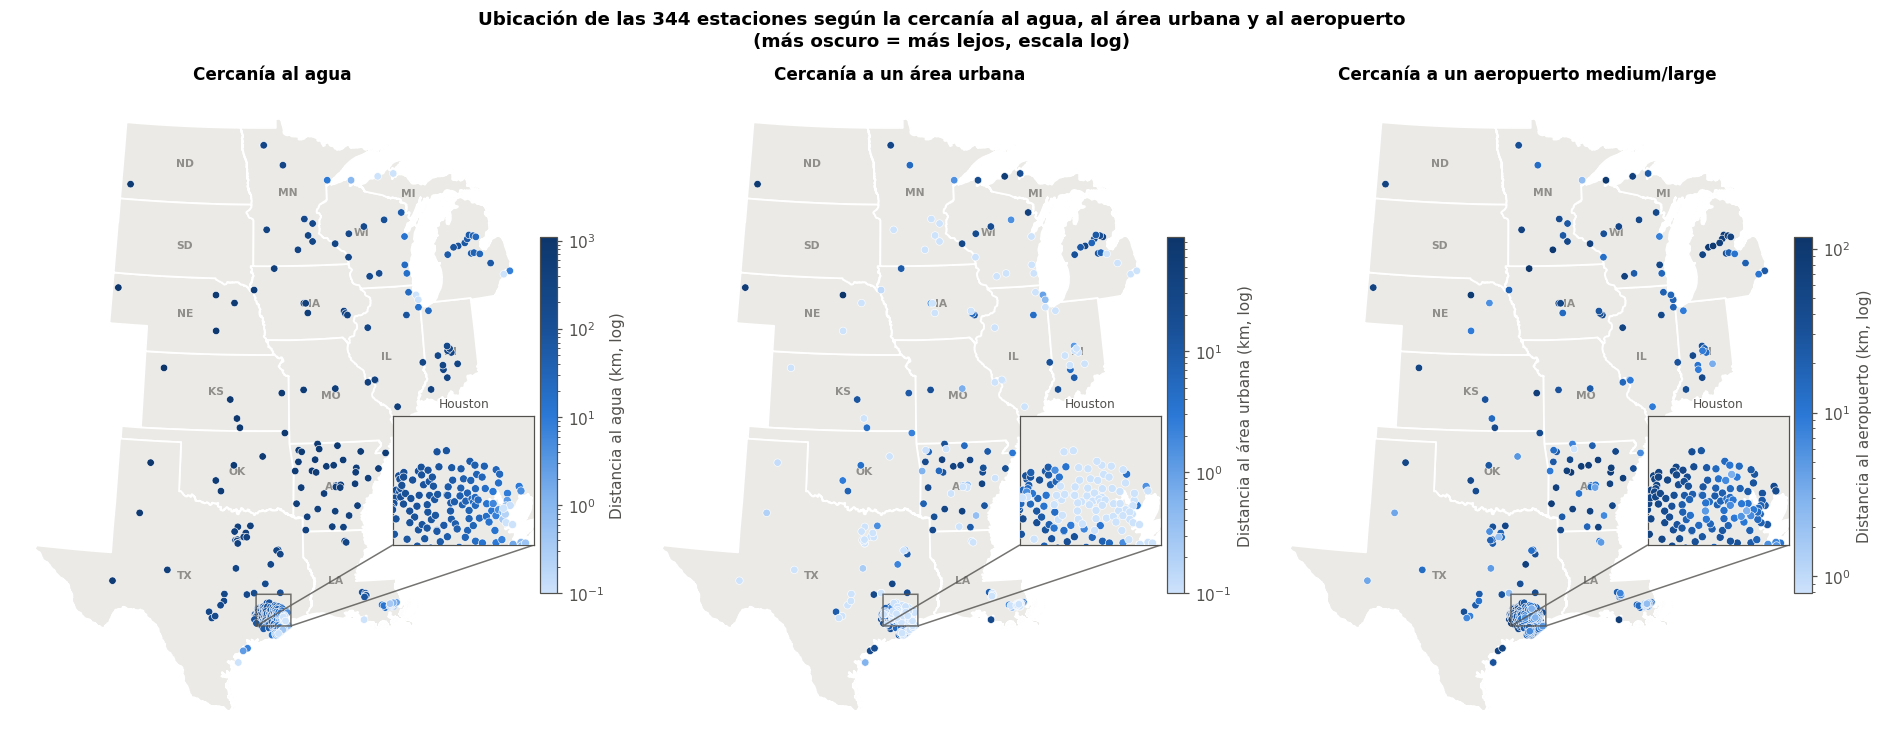

In [5]:
MAPAS = [
    ('dist_agua_km', 'Distancia al agua (km, log)', 'Cercanía al agua'),
    ('dist_area_urbana_km', 'Distancia al área urbana (km, log)', 'Cercanía a un área urbana'),
    ('dist_aeropuerto_km', 'Distancia al aeropuerto (km, log)', 'Cercanía a un aeropuerto medium/large'),
]

fig, axes = plt.subplots(1, 3, figsize=(17, 7), constrained_layout=True)
for ax, (columna, etiqueta, titulo) in zip(axes, MAPAS):
    mapa_cercania(ax, columna, etiqueta, titulo)
titulo_fig = (f'Ubicación de las {len(gdf)} estaciones según la cercanía al agua, al área urbana y al aeropuerto'
             + chr(10) + '(más oscuro = más lejos, escala log)')
fig.suptitle(titulo_fig, fontweight='bold')
figuras['00_mapas_cercania'] = fig

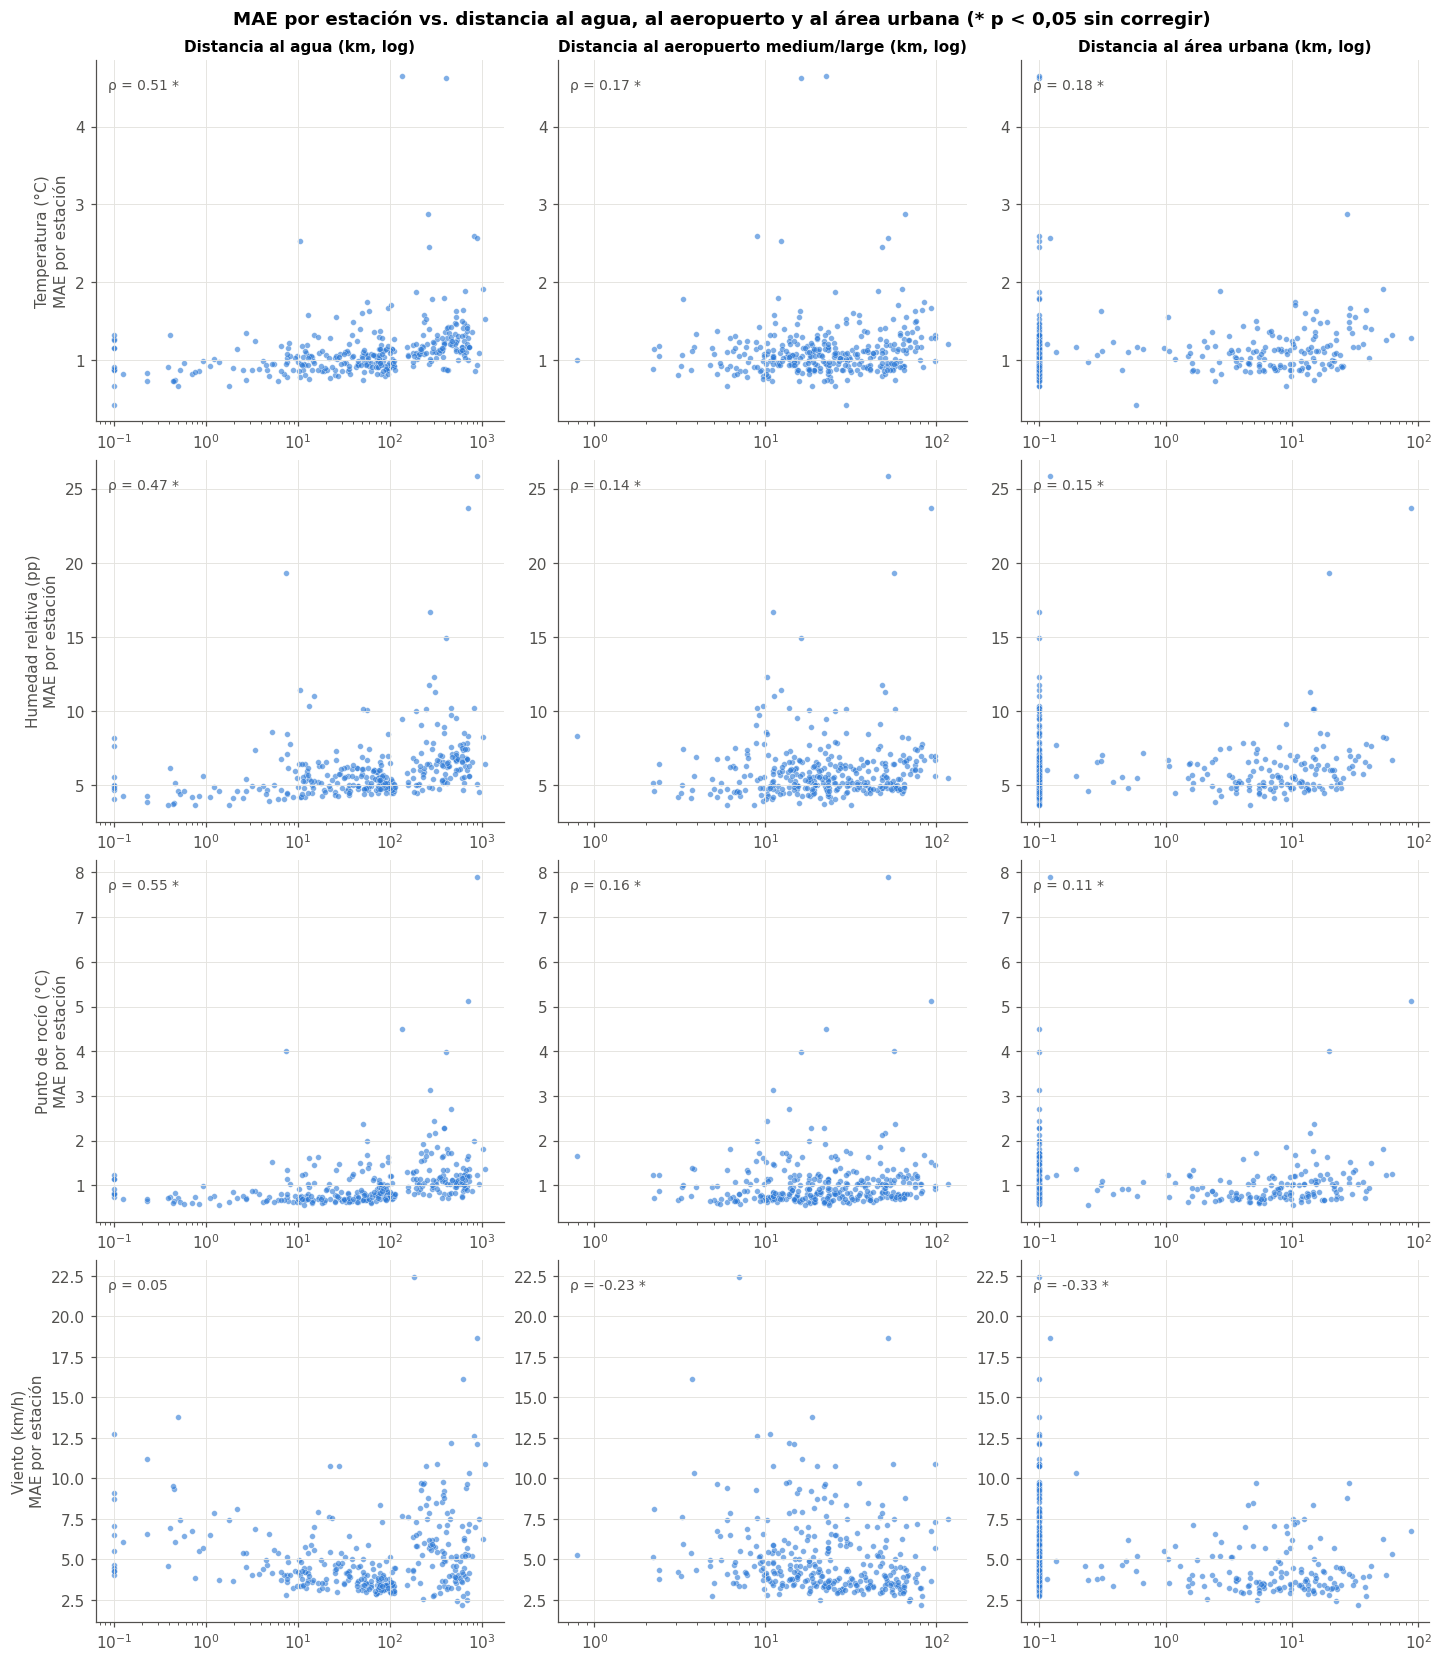

In [6]:
DISTANCIAS = [
    ('dist_agua_km', 'Distancia al agua (km, log)'),
    ('dist_aeropuerto_km', 'Distancia al aeropuerto medium/large (km, log)'),
    ('dist_area_urbana_km', 'Distancia al área urbana (km, log)'),
]

fig, axes = plt.subplots(4, 3, figsize=(13, 15), constrained_layout=True)
for i, (var, etiqueta) in enumerate(VARIABLES.items()):
    for j, (col_dist, etiqueta_dist) in enumerate(DISTANCIAS):
        ax = axes[i, j]
        sub = datos[[col_dist, f'abs_error_{var}']].dropna()  # algunas estaciones no miden esta variable
        x = sub[col_dist].clip(lower=0.1)  # la escala log no admite 0 (estaciones adentro del área/agua)
        y = sub[f'abs_error_{var}']
        rho, p = stats.spearmanr(x, y)
        ax.scatter(x, y, s=14, color=AZUL, alpha=0.6, edgecolor='white', linewidth=0.3)
        ax.set_xscale('log')
        ax.text(0.03, 0.95, f'ρ = {rho:.2f}' + (' *' if p < 0.05 else ''), transform=ax.transAxes,
                va='top', fontsize=9, color=GRIS_TEXTO)
        if i == 0:
            ax.set_title(etiqueta_dist, fontsize=10)
        if j == 0:
            ax.set_ylabel(f'{etiqueta}\nMAE por estación')
fig.suptitle('MAE por estación vs. distancia al agua, al aeropuerto y al área urbana (* p < 0,05 sin corregir)',
             fontweight='bold')
figuras['01_mae_vs_distancias'] = fig

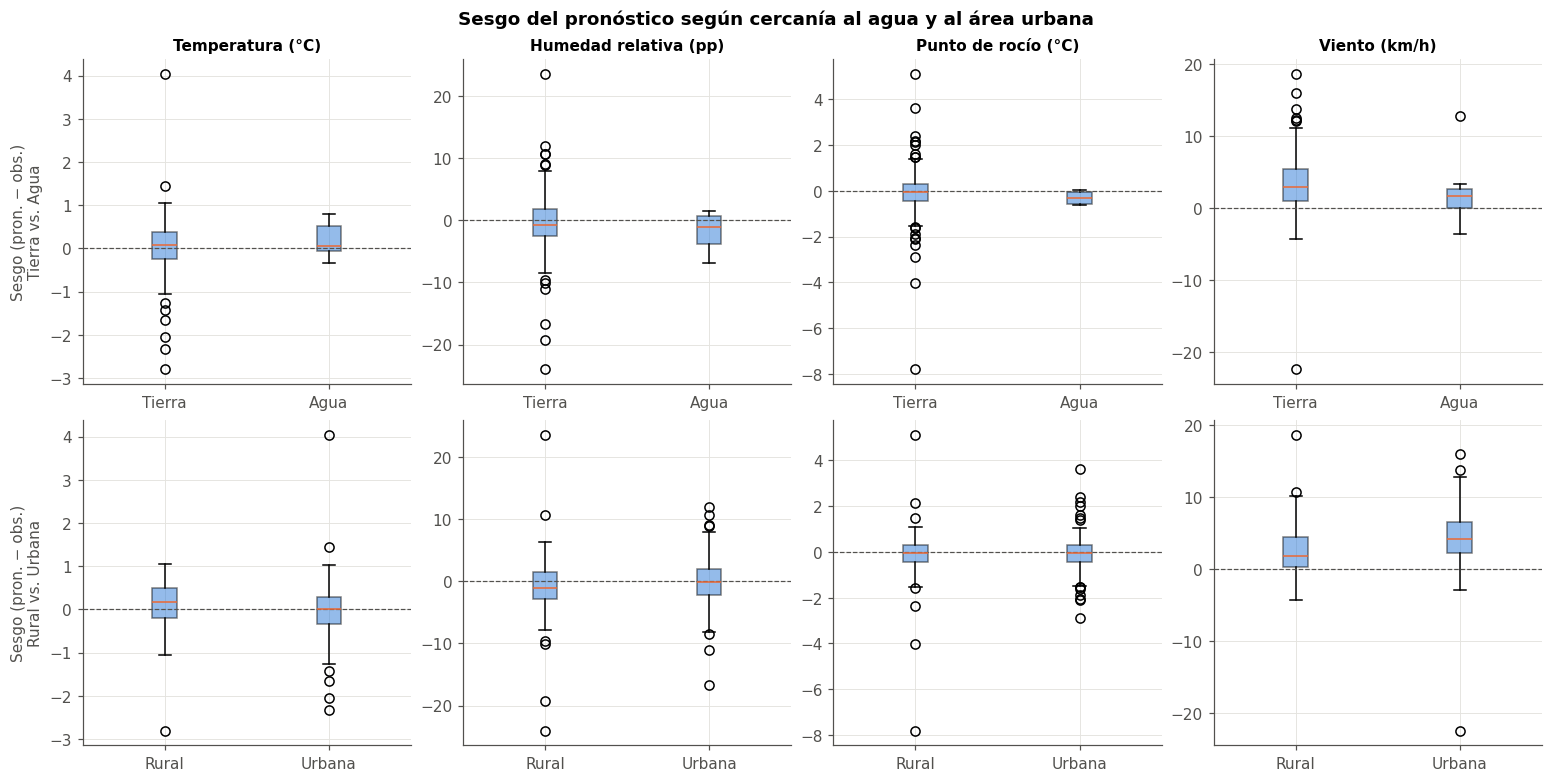

In [7]:
GRUPOS = [('sobre_agua', 'Tierra', 'Agua'), ('en_area_urbana', 'Rural', 'Urbana')]

fig, axes = plt.subplots(2, 4, figsize=(14, 7), constrained_layout=True)
for i, (col_grupo, etiqueta_no, etiqueta_si) in enumerate(GRUPOS):
    for j, (var, etiqueta) in enumerate(VARIABLES.items()):
        ax = axes[i, j]
        grupos = [datos.loc[~datos[col_grupo], f'error_{var}'].dropna(),
                  datos.loc[datos[col_grupo], f'error_{var}'].dropna()]
        ax.boxplot(grupos, tick_labels=[etiqueta_no, etiqueta_si], patch_artist=True,
                   boxprops=dict(facecolor=AZUL, alpha=0.5), medianprops=dict(color=NARANJA))
        ax.axhline(0, color=GRIS_TEXTO, lw=0.8, ls='--')
        if i == 0:
            ax.set_title(etiqueta, fontsize=10)
        if j == 0:
            ax.set_ylabel(f'Sesgo (pron. − obs.)\n{etiqueta_no} vs. {etiqueta_si}')
fig.suptitle('Sesgo del pronóstico según cercanía al agua y al área urbana', fontweight='bold')
figuras['02_sesgo_grupos'] = fig

### Lectura rápida de los mapas

El mapa del área urbana y el del aeropuerto son casi calcos uno del otro (ρ de Spearman = 0,69 entre ambas
distancias): no sorprende, porque los aeropuertos medium/large suelen estar junto a las ciudades grandes. El
mapa del agua es un patrón distinto (ρ ≈ 0,22–0,23 con los otros dos) — se nota, por ejemplo, en el noreste de
Wisconsin/Michigan, claro en el mapa del agua (cerca de los Grandes Lagos) pero oscuro en los otros dos. El
recuadro de Houston es la zona más clara en los tres mapas a la vez. Esta correlación moderada entre
`dist_area_urbana_km` y `dist_aeropuerto_km` hay que tenerla presente al leer la sección 3: cuando las dos salen
significativas en la misma dirección, puede ser el mismo efecto contado dos veces.

### Lectura rápida de los gráficos

- **Agua**: en temperatura, HR y punto de rocío el MAE sube con la distancia al agua (nubes de puntos con pendiente
  positiva clara); en viento no hay patrón (nube plana, ρ ≈ 0).
- **Aeropuerto**: patrón más débil pero en la misma dirección para las 4 variables (MAE sube al alejarse), salvo el
  viento, donde va al revés: el MAE **baja** al alejarse del aeropuerto.
- **Área urbana**: mismo patrón que aeropuerto — MAE de temperatura/HR/punto de rocío sube al alejarse (estaciones
  urbanas con mejor pronóstico), MAE de viento baja al alejarse (estaciones urbanas con peor pronóstico de viento).
- **Boxplots**: el sesgo del viento es positivo (sobreestimado) tanto en tierra como en agua y tanto en área urbana
  como rural, pero visiblemente mayor en área urbana. En las otras 3 variables las cajas de agua/tierra y
  urbana/rural se superponen casi por completo: a ojo no hay diferencia clara, hay que confirmarlo con los tests.

## 3. Pruebas de significancia

Los tres tests que siguen son no paramétricos (basados en rangos, no en la media/varianza) porque el error de
pronóstico tiene colas pesadas — la Etapa A midió una curtosis de 1,1 a 5,5 en las 4 variables con QQ-plots —, así que
no conviene asumir que es normal. Los no paramétricos no necesitan ese supuesto y son menos sensibles a unas pocas
estaciones extremas.

- **Spearman (ρ)**: correlación entre dos variables continuas, pero calculada sobre sus rangos en vez de sus valores.
  H0: no hay relación monótona (ρ = 0). Se usa para `dist_*` (continua) vs. MAE por estación: no exige que la
  relación sea lineal, solo que sea creciente o decreciente, que es lo esperable acá ("más lejos, pronóstico algo
  peor o mejor", no necesariamente en línea recta).
- **Mann-Whitney U**: compara dos grupos independientes para ver si uno tiende a tener valores más altos que el
  otro (equivalente no paramétrico del t-test de dos muestras). H0: las dos distribuciones son iguales. Se usa para
  los grupos binarios (agua/tierra, urbana/rural) contra el MAE y contra el sesgo con signo.
- **Wilcoxon de una muestra**: para una sola serie de valores, prueba si su mediana es distinta de un valor de
  referencia (acá, 0). H0: mediana del sesgo = 0. Es el equivalente no paramétrico del t-test de una muestra. Se usa
  para la validación de sesgo direccional: dentro de cada subgrupo (p. ej. "estaciones sobre el agua"), ¿el sesgo
  que se ve en el boxplot es distinto de cero o podría ser ruido?

Los tres comparan su estadístico contra una distribución de referencia para obtener un p-valor, y la regla de
decisión es la misma para los tres: se rechaza H0 si el p-valor (ajustado por FDR, ver abajo) es menor a α = 0,05.

| Test | Estadístico | Cómo se obtiene el p-valor |
|---|---|---|
| Spearman | ρ (correlación de los rangos) | Bajo H0 (ρ = 0), para n grande el estadístico t = ρ·√((n−2)/(1−ρ²)) sigue aproximadamente una t de Student con n−2 grados de libertad (`scipy.stats.spearmanr`). |
| Mann-Whitney U | U (relacionado con la suma de rangos de un grupo) | Bajo H0 (mismas distribuciones), U se aproxima a una normal para n no muy chico (`scipy.stats.mannwhitneyu`). |
| Wilcoxon de una muestra | W (suma de rangos con signo de los valores ≠ 0) | Bajo H0 (mediana = 0), W se aproxima a una normal para n moderado (`scipy.stats.wilcoxon`); por eso se exige n ≥ 10 en `tabla_sesgo`, donde esa aproximación deja de ser confiable. |

Con 28 tests en `tabla_asociacion` y 12 en `tabla_sesgo`, corregir por comparaciones múltiples es necesario (si se
testean 28 hipótesis al 5 %, se esperan ~1,4 falsos positivos solo por azar). Se usa FDR de Benjamini-Hochberg en vez
de Bonferroni: controla la proporción esperada de falsos positivos entre los resultados significativos, pero es
menos conservador, lo que conviene con un n de estaciones moderado (no miles).

En ambas tablas se reporta el tamaño de efecto (ρ o diferencia de medias/mediana) además del p-valor, y el n es el
número de **estaciones**, no de mediciones (una fila por estación, como se armó en la sección 1, para no inflar el
n con horas autocorrelacionadas).

In [8]:
resultados_asociacion = []

for var, etiqueta in VARIABLES.items():
    for col_dist, etiqueta_dist in DISTANCIAS:
        sub = datos[[col_dist, f'abs_error_{var}']].dropna()  # algunas estaciones no miden esta variable
        rho, p = stats.spearmanr(sub[col_dist], sub[f'abs_error_{var}'])
        resultados_asociacion.append(dict(
            variable=etiqueta, atributo=etiqueta_dist, tipo='Spearman (MAE)',
            efecto=round(rho, 3), p=p, n=len(sub)))

    for col_grupo, etiqueta_no, etiqueta_si in GRUPOS:
        for sufijo, nombre_tipo in [('abs_error', 'MAE'), ('error', 'sesgo')]:
            a = datos.loc[datos[col_grupo], f'{sufijo}_{var}'].dropna()
            b = datos.loc[~datos[col_grupo], f'{sufijo}_{var}'].dropna()
            _, p = stats.mannwhitneyu(a, b, alternative='two-sided')
            resultados_asociacion.append(dict(
                variable=etiqueta, atributo=f'{etiqueta_si} vs. {etiqueta_no}',
                tipo=f'Mann-Whitney ({nombre_tipo})', efecto=round(a.mean() - b.mean(), 3),
                p=p, n=len(a) + len(b)))

tabla_asociacion = pd.DataFrame(resultados_asociacion)
tabla_asociacion['p_fdr'] = multipletests(tabla_asociacion['p'], method='fdr_bh')[1]
tabla_asociacion['significativo'] = tabla_asociacion['p_fdr'] < 0.05
tabla_asociacion = tabla_asociacion.sort_values('p_fdr').reset_index(drop=True)
print(f'{tabla_asociacion["significativo"].sum()} de {len(tabla_asociacion)} tests significativos tras FDR (q < 0,05)')
tabla_asociacion.round(4)

14 de 28 tests significativos tras FDR (q < 0,05)


,variable,atributo,tipo,efecto,p,n,p_fdr,significativo
0,Punto de rocío (°C),"Distancia al agua (km, log)",Spearman (MAE),0.551,0.0000,330,0.0000,True
1,Temperatura (°C),"Distancia al agua (km, log)",Spearman (MAE),0.512,0.0000,340,0.0000,True
2,Humedad relativa (pp),"Distancia al agua (km, log)",Spearman (MAE),0.465,0.0000,330,0.0000,True
3,Viento (km/h),"Distancia al área urbana (km, log)",Spearman (MAE),-0.325,0.0000,334,0.0000,True
4,Viento (km/h),Urbana vs. Rural,Mann-Whitney (sesgo),1.939,0.0000,334,0.0000,True
5,Viento (km/h),Urbana vs. Rural,Mann-Whitney (MAE),1.312,0.0000,334,0.0000,True
6,Viento (km/h),"Distancia al aeropuerto medium/large (km, log)",Spearman (MAE),-0.231,0.0000,334,0.0001,True
7,Temperatura (°C),"Distancia al área urbana (km, log)",Spearman (MAE),0.176,0.0011,340,0.0039,True
8,Temperatura (°C),"Distancia al aeropuerto medium/large (km, log)",Spearman (MAE),0.171,0.0016,340,0.0050,True
9,Punto de rocío (°C),"Distancia al aeropuerto medium/large (km, log)",Spearman (MAE),0.160,0.0037,330,0.0102,True


In [9]:
resultados_sesgo = []

for var, etiqueta in VARIABLES.items():
    for col_grupo, etiqueta_no, etiqueta_si in GRUPOS:
        for pertenece, nombre_grupo in [(True, etiqueta_si), (False, etiqueta_no)]:
            serie = datos.loc[datos[col_grupo] == pertenece, f'error_{var}'].dropna()
            serie = serie[serie != 0]  # wilcoxon no admite diferencias en cero
            if len(serie) < 10:
                estadistico, p = np.nan, np.nan
            else:
                _, p = stats.wilcoxon(serie)
                estadistico = serie.median()
            resultados_sesgo.append(dict(
                variable=etiqueta, grupo=f'{nombre_grupo} ({col_grupo})',
                mediana_sesgo=round(estadistico, 3) if pd.notna(estadistico) else np.nan,
                n=len(serie), p=p))

tabla_sesgo = pd.DataFrame(resultados_sesgo)
valida = tabla_sesgo['p'].notna()
tabla_sesgo.loc[valida, 'p_fdr'] = multipletests(tabla_sesgo.loc[valida, 'p'], method='fdr_bh')[1]
tabla_sesgo['significativo'] = tabla_sesgo['p_fdr'] < 0.05
tabla_sesgo = tabla_sesgo.sort_values('p_fdr').reset_index(drop=True)
print(f'{tabla_sesgo["significativo"].sum()} de {valida.sum()} tests con mediana != 0 significativos tras FDR (q < 0,05)'
      f' ({(~valida).sum()} sin test por n < 10)')
tabla_sesgo.round(4)

7 de 12 tests con mediana != 0 significativos tras FDR (q < 0,05) (4 sin test por n < 10)


,variable,grupo,mediana_sesgo,n,p,p_fdr,significativo
0,Viento (km/h),Tierra (sobre_agua),2.855,327,0.0000,0.0000,True
1,Viento (km/h),Urbana (en_area_urbana),4.177,164,0.0000,0.0000,True
2,Viento (km/h),Rural (en_area_urbana),1.789,170,0.0000,0.0000,True
3,Temperatura (°C),Rural (en_area_urbana),0.172,174,0.0004,0.0011,True
4,Humedad relativa (pp),Rural (en_area_urbana),-1.048,168,0.0021,0.0050,True
5,Humedad relativa (pp),Tierra (sobre_agua),-0.673,326,0.0157,0.0269,True
6,Temperatura (°C),Tierra (sobre_agua),0.086,333,0.0145,0.0269,True
7,Punto de rocío (°C),Tierra (sobre_agua),-0.051,326,0.0981,0.1471,False
8,Punto de rocío (°C),Urbana (en_area_urbana),-0.066,162,0.1840,0.2453,False
9,Punto de rocío (°C),Rural (en_area_urbana),-0.046,168,0.2227,0.2672,False


### Conclusiones

**14 de los 28 tests de asociación son significativos tras FDR** (q < 0,05, `tabla_asociacion`):

- **Agua**: se asocia al MAE de temperatura (ρ = 0,51), humedad relativa (ρ = 0,47) y punto de rocío (ρ = 0,55) —
  las tres con p < 0,0001 —, pero **no** al de viento (ρ = 0,05, p = 0,41). Cuanto más lejos del agua, peor el
  pronóstico de las variables ligadas a la humedad. La comparación agua/tierra (grupo binario) **no** sale
  significativa para ninguna variable, probablemente por falta de potencia: solo 7 estaciones sobre el agua con
  suficientes pares.
- **Aeropuerto**: se asocia al MAE de temperatura (ρ = 0,17), humedad relativa (ρ = 0,14) y punto de rocío
  (ρ = 0,16), todas con signo positivo (más lejos del aeropuerto, peor el pronóstico) y p < 0,05 — coherente con que
  el modelo del NWS se calibra con ASOS. El viento va al revés: ρ = −0,23 (p = 0,0001), **peor** pronóstico cerca de
  un aeropuerto, posiblemente por ráfagas y turbulencia propias de pistas y edificios.
- **Área urbana**: mismo patrón que aeropuerto en temperatura (ρ = 0,18), HR (ρ = 0,15) y viento (ρ = −0,33, el
  efecto más fuerte de toda la tabla); punto de rocío queda apenas afuera tras FDR (q = 0,10). La comparación
  urbana/rural confirma el viento: sesgo +1,94 km/h y MAE +1,31 km/h más alto en área urbana (ambos p < 0,0001).

**Validación del sesgo direccional** (`tabla_sesgo`, 7 de 12 tests con n suficiente son significativos): el sesgo de
viento es positivo y significativo en los cuatro subgrupos con n suficiente (tierra +2,86 km/h, urbana +4,18 km/h,
rural +1,79 km/h), es decir, **la sobreestimación del viento de la Etapa A no es un artefacto de la zona de Houston**:
aparece en tierra y se duplica en área urbana. Temperatura y HR tienen sesgos pequeños pero significativos en tierra
y en zona rural (p < 0,02), demasiado chicos para ser relevantes en la práctica (+0,09 °C, −0,67 pp). En las
estaciones sobre el agua no se pudo testear el sesgo (n = 4–7, por debajo del mínimo de 10 que pide Wilcoxon).

## 4. Control por red (confusión con la ubicación)

`CENTERPOINT` es, con 148 de las 500 estaciones, la red más grande del dataset — probablemente de CenterPoint
Energy, la eléctrica que da servicio a Houston, que instala sus propios sensores para monitorear tormentas e
inundaciones — y están todas concentradas en esa ciudad, que además es la zona más urbana del dataset. Eso deja
la red confundida con la ubicación: cualquier diferencia que se atribuya a "área urbana" podría ser en
realidad un efecto propio de esta red (sensores, exposición, calibración) y no de estar en una ciudad. Se
repite entonces el Mann-Whitney de `en_area_urbana` sobre el MAE excluyendo CENTERPOINT, para ver si el efecto
sobrevive o era solo esa red.

In [10]:
sin_centerpoint = datos[datos['red'] != 'CENTERPOINT']
print(f'Estaciones sin CENTERPOINT: {len(sin_centerpoint)} de {len(datos)} '
      f'({len(datos) - len(sin_centerpoint)} excluidas)')

resultados_control = []
for var, etiqueta in VARIABLES.items():
    a = sin_centerpoint.loc[sin_centerpoint['en_area_urbana'], f'abs_error_{var}'].dropna()
    b = sin_centerpoint.loc[~sin_centerpoint['en_area_urbana'], f'abs_error_{var}'].dropna()
    if len(a) < 5 or len(b) < 5:
        resultados_control.append(dict(variable=etiqueta, diferencia_mae=np.nan, p=np.nan,
                                       n_urbana=len(a), n_rural=len(b)))
        continue
    _, p = stats.mannwhitneyu(a, b, alternative='two-sided')
    resultados_control.append(dict(variable=etiqueta, diferencia_mae=round(a.mean() - b.mean(), 3),
                                   p=p, n_urbana=len(a), n_rural=len(b)))

tabla_control = pd.DataFrame(resultados_control)
tabla_control.round(4)

Estaciones sin CENTERPOINT: 196 de 344 (148 excluidas)


,variable,diferencia_mae,p,n_urbana,n_rural
0,Temperatura (°C),0.002,0.0140,93,99
1,Humedad relativa (pp),-0.315,0.1785,89,93
2,Punto de rocío (°C),-0.006,0.9417,89,93
3,Viento (km/h),1.360,0.0002,91,95


### Conclusión del control

El efecto del viento **sobrevive** sin CENTERPOINT: el MAE sigue siendo +1,36 km/h mayor en área urbana (p = 0,0002,
muy cerca del +1,31 km/h de la muestra completa), así que no es un artefacto de esa única red — otras estaciones
urbanas (WEATHERSTEM, APRSWXNET en pueblos, etc.) muestran el mismo patrón. El de temperatura se mantiene
significativo pero el efecto es prácticamente nulo (+0,002 °C): significancia estadística sin relevancia práctica,
con este n. El de HR y punto de rocío **no sobreviven**: p = 0,18 y p = 0,94 sin CENTERPOINT, así que la asociación
que aparecía en `tabla_asociacion` para estas dos variables estaba confundida con esa red (es decir, era more bien
"efecto Houston" que "efecto área urbana" en general).

## 5. Síntesis de la hipótesis

**Los datos respaldan la hipótesis de manera parcial, y de forma distinta según la variable y el atributo:**

1. **Agua**: Existe una asociación clara con el MAE de temperatura, HR y punto de rocío (ρ entre 0,47 y 0,55), no con el de
   viento. Es el efecto más consistente de los tres, pero se apoya en la distancia continua. Por otro lado, el grupo "sobre el
   agua" tiene muy pocas estaciones (7) para confirmar la diferencia de grupo con potencia suficiente.
2. **Aeropuerto/ASOS** (distancia a aeropuertos medium/large): Hay una asociación significativa y en la dirección
   esperada para temperatura, HR y punto de rocío (cuanto más lejos se encuentra una estación del aeropuerto, peor resulta el pronóstico), coherente con que
   el modelo se calibra contra ASOS. El viento muestra el patrón inverso.
3. **Área urbana**: el hallazgo más sólido es el del **viento**, robusto al control por red (+1,3 a +1,4 km/h de MAE
   en área urbana, con o sin CENTERPOINT) y con sesgo direccional significativo en ambos subgrupos (urbana y rural).
   Los efectos en temperatura, HR y punto de rocío son más débiles y, en el caso de HR y punto de rocío, **no
   sobreviven** al excluir CENTERPOINT.

## 6. Exportación de las figuras y las tablas

In [11]:
import os

os.makedirs(OUT, exist_ok=True)
for nombre, fig in figuras.items():
    fig.savefig(OUT + f'{nombre}.png', dpi=300, bbox_inches='tight', facecolor='white')
tabla_asociacion.to_csv(OUT + 'tabla_asociacion_h7.csv', index=False)
tabla_sesgo.to_csv(OUT + 'tabla_sesgo_direccional_h7.csv', index=False)
tabla_control.to_csv(OUT + 'tabla_control_red_h7.csv', index=False)
print(f'Guardados: {len(figuras)} figuras y 3 tablas en {OUT}')

Guardados: 3 figuras y 3 tablas en ../data/processed/hipotesis/
